# Oral condition classifier (6 classes)

**IT2226 AI Innovator and Deep Learning Project: Dental Health Awareness and Affordability in Singapore**

This notebook trains and evaluates the image classifier that closes the brief's **detection gap**. It takes an intraoral photo and returns probabilities for the six classes in [`shared/conditions.yaml`](../../../../shared/conditions.yaml): calculus, caries, hypodontia, mouth ulcer, normal and tooth discoloration. The saved checkpoint (`models/classifier/weights/Daniel/best.pt`) feeds the cost calculator and the agent.

> **Scope.** This is a *screening and education aid*. It does not diagnose, and its output must always be presented with a recommendation to see a dentist. The model cannot see gum disease (not a labelled class), so a "normal" result never means "healthy gums".

### Brief data issues and how this notebook handles them

| Issue (brief §4, plus what we found) | What this notebook does | Section |
|---|---|---|
| Uneven classes (Caries 219 vs Calculus 1,296) | Measures the *real* imbalance after de-duplication; class- and group-balanced sampling; macro-F1 / balanced accuracy as headline metrics; adds external caries photos (ablation) | 3, 5, 6 |
| **Found:** Kaggle ships with pre-augmented copies and duplicates (rotated, sheared and recoloured copies; byte-identical files) | Exact + perceptual (pHash) + CNN-embedding near-duplicate grouping; **group-aware** splits so copies never straddle train/test; test on one image per group | 3, 4 |
| One label per image, even when a mouth shows several conditions | Detects identical photos filed under different classes, keeps them out of val/test; reports top-2 probabilities rather than a hard label | 3, 9 |
| Image quality, lighting and framing vary | Quality EDA per class (resolution, brightness, sharpness); strong photometric + JPEG/blur augmentation; robustness test under degraded photos; abstention threshold | 2, 5, 8 |
| **Found:** the Normal class comes from a different camera source (phone photos, ~10x the resolution) | Every image is resized into a common cache; JPEG/blur augmentation; explicit resolution-shortcut test | 2, 8 |
| Images are not from Singapore patients | External test on two independent datasets (Zenodo, DentalAI) plus Mendeley; discussed as a limitation | 7, 10 |
| Gum disease is not a labelled class | Cannot be fixed with this data; documented and passed to the app via the checkpoint notes | 10 |

### Which datasets in `data/raw/` are used

| Folder | What it contains | Used for |
|---|---|---|
| `kaggle_oral/` | The brief's core dataset: 4,375 photos, 6 single-label classes | **Main train / val / test** |
| `zenodo/Benchmarking Dataset/` | Intraoral photos with caries bounding boxes (`d`, `D` = decayed deciduous / permanent tooth). About 2,200 annotated images; the rest of the image folder has no labels | Extra **caries** training images (capped) + external caries test. The unannotated images are ignored |
| `dentalai/` | Roboflow export with Tooth / Caries / Cavity / Crack polygons | Extra **caries** training images (capped) + external test. Images that duplicate Kaggle photos are removed first |
| `mendeley_noncaries/` | 9.5k clinical tooth photos grouped by *view* only (no condition labels) | Not trained on (no 6-class labels). A sample is used as an external **caries false-positive** check |
| `zenodo/Dataset/` | Full Zenodo release (same source as the benchmark split) | Not used, because the benchmark split already covers it with clean annotations |

Run `python models/classifier/notebooks/Daniel/setup.py` first to download the Kaggle data. The other folders are listed in `Dataset links.md`.

## 0. Setup

In [ ]:
# Install the notebook's dependencies into THIS kernel's Python environment.
# Safe to re-run: only missing packages are installed. Restart the kernel afterwards if anything was installed.
import importlib.util, subprocess, sys

PACKAGES = {  # import name -> pip package
    "numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
    "matplotlib": "matplotlib", "PIL": "pillow", "cv2": "opencv-python", "yaml": "pyyaml",
    "tqdm": "tqdm", "IPython": "ipython", "kagglehub": "kagglehub",
}
# PyTorch comes from its own index so the GPU build is installed (plain `pip install torch` gives the CPU build on Windows).
# CUDA 12.8 wheels support RTX 50-series cards; use "https://download.pytorch.org/whl/cpu" on a machine without an NVIDIA GPU.
TORCH_INDEX = "https://download.pytorch.org/whl/cu128"


def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])


installed = []
missing = [pkg for mod, pkg in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("installing:", " ".join(missing))
    pip_install(*missing); installed += missing
if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
    print("installing torch + torchvision from", TORCH_INDEX)
    pip_install("torch", "torchvision", "--index-url", TORCH_INDEX); installed += ["torch", "torchvision"]

import torch, torchvision
tv_version = tuple(int(x) for x in torchvision.__version__.split("+")[0].split(".")[:2])
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__} | "
      f"CUDA available: {torch.cuda.is_available()}")
if tv_version < (0, 20):
    print("WARNING: torchvision >= 0.20 is needed (v2.JPEG augmentation). Upgrade with:\n"
          f"  {sys.executable} -m pip install -U torch torchvision --index-url {TORCH_INDEX}")
if not torch.cuda.is_available():
    print("NOTE: no GPU visible. The notebook still runs on CPU, but training will be very slow.")
if installed:
    print("Installed packages: restart the kernel, then run the notebook from the next cell.")


installing: kagglehub
python 3.13.14 | torch 2.15.0+cu134 | torchvision 0.29.2+cu134 | CUDA available: True
Installed packages: restart the kernel, then run the notebook from the next cell.


In [1]:
import os, re, io, json, glob, time, math, copy, random, hashlib, warnings, datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import cv2
from PIL import Image, ImageOps, ImageFilter, ImageEnhance
from scipy.fft import dctn
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision as tv
from torchvision.transforms import v2
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_auc_score, precision_recall_fscore_support)
from tqdm import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
Image.MAX_IMAGE_PIXELS = None
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def find_repo_root():
    # Look upwards for shared/conditions.yaml from: $DLWIU_ROOT (manual override), the kernel's working
    # directory, and the notebook's own folder (VS Code exposes it as __vsc_ipynb_file__).
    starts = []
    if os.environ.get("DLWIU_ROOT"):
        starts.append(Path(os.environ["DLWIU_ROOT"]))
    starts.append(Path.cwd())
    if "__vsc_ipynb_file__" in globals():
        starts.append(Path(globals()["__vsc_ipynb_file__"]).parent)
    for s in starts:
        for p in [s, *s.parents]:
            if (p / "shared" / "conditions.yaml").exists():
                return p.resolve()
    raise FileNotFoundError(
        f"Could not find the Deep-Learning-WIU repo (looked upwards from {[str(s) for s in starts]}). "
        "Open the notebook from inside the repo, or set it manually before this cell: "
        "os.environ['DLWIU_ROOT'] = r'C:\\path\\to\\Deep-Learning-WIU'")


ROOT = find_repo_root()
RAW = ROOT / "data" / "raw"
CACHE_DIR = ROOT / "data" / "interim" / "classifier_cache"   # resized copies of every image (gitignored)
PROC = ROOT / "data" / "processed" / "classifier"            # feature caches (gitignored)
MANIFESTS = ROOT / "manifests"                               # split CSV (committed: reproducible without data)
WEIGHTS = ROOT / "models" / "classifier" / "weights" / "Daniel"   # checkpoints (gitignored)
RESULTS = ROOT / "models" / "classifier" / "results"         # metrics + figures for the report
FIGS = RESULTS / "figures"
for d in [CACHE_DIR, PROC, MANIFESTS, WEIGHTS, RESULTS, FIGS]:
    d.mkdir(parents=True, exist_ok=True)

CFG = dict(
    seed=42,
    cache_max_side=384,          # every image is stored at <=384 px so all sources share a resolution
    img_size=224,
    backbone="convnext_tiny",    # also supported: efficientnet_b0, resnet50
    epochs=25, patience=6, batch_size=32,
    lr=1e-4, weight_decay=0.05, warmup_epochs=1,
    dup_phash_max_hamming=6,     # pHash distance <= 6 bits  -> same photo
    dup_cosine_min=0.90,         # CNN embedding cosine >= 0.90 -> same photo (rotated / sheared / recoloured)
    ext_dup_cosine_min=0.95,     # stricter inside the clinical sets, where different patients' photos look alike
    min_side_px=64,              # drop thumbnails smaller than this
    test_frac=0.15, val_frac=0.15,
    ext_caries_train_per_source=200,   # cap on external caries photos added in experiment C
    mendeley_sample=600,
    target_selective_accuracy=0.95,    # abstain below the confidence that reaches this accuracy on val
    min_abstain_conf=0.50,             # ...and never answer with a top probability below this
    max_ext_false_caries=0.15,         # selection guardrail: false-caries rate on external caries-free val photos
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.is_bf16_supported()) else torch.float16


def seed_everything(seed=CFG["seed"]):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


seed_everything()
torch.backends.cudnn.benchmark = True
print("repo root:", ROOT)
print("torch", torch.__version__, "| torchvision", tv.__version__, "| device:", DEVICE,
      torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

repo root: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU
torch 2.15.0+cu134 | torchvision 0.29.2+cu134 | device: cuda NVIDIA GeForce RTX 5070 Ti


In [2]:
# Class IDs come from the shared single source of truth, never re-numbered here.
conditions = yaml.safe_load(open(ROOT / "shared" / "conditions.yaml"))["conditions"]
conditions = sorted(conditions, key=lambda c: c["id"])
assert [c["id"] for c in conditions] == list(range(len(conditions))), "class ids must be 0..N-1"
CLASSES = [c["name"] for c in conditions]
DISPLAY = {c["name"]: c["display_name"] for c in conditions}
SRC2NAME = {c["source_label"].lower(): c["name"] for c in conditions}
CLS2ID = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
CARIES = CLS2ID["caries"]
pd.DataFrame(conditions)[["id", "name", "display_name", "source_label"]]

,id,name,display_name,source_label
0,0,calculus,Calculus (tartar),Calculus
1,1,caries,Dental caries,caries
2,2,hypodontia,Hypodontia,Hypodontia
3,3,mouth_ulcer,Mouth ulcer,Mouth ulcer
4,4,normal,No visible condition,Normal
5,5,tooth_discoloration,Tooth discoloration,tooth discoloration


## 1. Index the datasets

Each image is read once and, in the same pass:
- an MD5 of the raw bytes is computed (exact duplicates);
- the image is EXIF-rotated, downsized to at most 384 px and cached as JPEG under `data/interim/classifier_cache/<md5>.jpg`. Training reads only this cache, so a 12 MP phone photo and a 600 px web image reach the model at the same resolution;
- a 64-bit perceptual hash (DCT pHash), brightness and sharpness (variance of the Laplacian) are measured.

In [3]:
def phash_bits(im):
    a = np.asarray(im.convert("L").resize((32, 32), Image.LANCZOS), dtype=np.float32)
    d = dctn(a, norm="ortho")[:8, :8].flatten()
    return (d > np.median(d[1:])).astype(np.uint8)


def load_rgb(src, max_side=None):
    # Open, honour EXIF orientation, convert to RGB and optionally downsize (fast JPEG draft decode).
    im = Image.open(src)
    if max_side and im.format == "JPEG":
        im.draft("RGB", (max_side, max_side))
    im = ImageOps.exif_transpose(im).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side), Image.LANCZOS)
    return im


def index_images(df, desc):
    # Adds md5, original size, cache path, pHash and simple quality stats. Cached images are reused.
    recs, bits = [], []
    for p in tqdm(df["path"], desc=desc):
        r = dict(ok=False, md5=None, orig_w=np.nan, orig_h=np.nan, cache=None, brightness=np.nan, sharpness=np.nan)
        h = np.zeros(64, np.uint8)
        try:
            b = Path(p).read_bytes()
            r["md5"] = hashlib.md5(b).hexdigest()
            with Image.open(io.BytesIO(b)) as im0:
                w, hgt = im0.size
                if im0.getexif().get(0x0112, 1) in (5, 6, 7, 8):   # EXIF says rotated 90 degrees
                    w, hgt = hgt, w
            r["orig_w"], r["orig_h"] = w, hgt
            cpath = CACHE_DIR / f"{r['md5']}.jpg"
            if not cpath.exists():
                load_rgb(io.BytesIO(b), CFG["cache_max_side"]).save(cpath, quality=95)
            im = Image.open(cpath).convert("RGB")
            gray = np.asarray(im.convert("L"))
            r.update(cache=str(cpath), ok=min(w, hgt) >= CFG["min_side_px"],
                     brightness=float(gray.mean()), sharpness=float(cv2.Laplacian(gray, cv2.CV_64F).var()))
            h = phash_bits(im)
        except Exception as e:  # unreadable / truncated file
            print("unreadable:", p, e)
        recs.append(r); bits.append(h)
    out = pd.concat([df.reset_index(drop=True), pd.DataFrame(recs)], axis=1)
    return out, np.stack(bits)

In [4]:
kaggle_dirs = list(RAW.glob("kaggle_oral/**/oral dataset"))
assert kaggle_dirs, "Kaggle data not found: run models/classifier/notebooks/Daniel/setup.py"
KAGGLE_DIR = kaggle_dirs[0]

rows = []
for d in sorted(p for p in KAGGLE_DIR.iterdir() if p.is_dir()):
    for f in sorted(d.iterdir()):
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append(dict(source="kaggle", path=str(f), label=SRC2NAME[d.name.lower()], patient=None))
kag, kag_bits = index_images(pd.DataFrame(rows), "kaggle")
kag["file_ext"] = kag.path.str.extract(r"\.(\w+)$")[0]
kag["megapixels"] = kag.orig_w * kag.orig_h / 1e6
print(f"{len(kag)} files | unreadable: {(kag.md5.isna()).sum()} | smaller than {CFG['min_side_px']} px: {(~kag.ok & kag.md5.notna()).sum()}")
kag.groupby("label").size().rename("images").to_frame().T


kaggle:   0%|          | 0/4375 [00:00<?, ?it/s]


kaggle:   2%|▏         | 68/4375 [00:00<00:06, 667.95it/s]


kaggle:   3%|▎         | 139/4375 [00:00<00:06, 685.10it/s]


kaggle:   5%|▍         | 208/4375 [00:00<00:06, 677.21it/s]


kaggle:   6%|▋         | 276/4375 [00:00<00:06, 672.28it/s]


kaggle:   8%|▊         | 344/4375 [00:00<00:06, 661.63it/s]

... (46 outputs left out)


kaggle:  99%|█████████▊| 4315/4375 [00:05<00:00, 907.51it/s]


kaggle: 100%|██████████| 4375/4375 [00:05<00:00, 745.07it/s]

4375 files | unreadable: 0 | smaller than 64 px: 99


label,calculus,caries,hypodontia,mouth_ulcer,normal,tooth_discoloration
images,1296,219,1251,265,286,1058


## 2. Exploratory analysis: imbalance, quality and source shortcuts

The brief warns that quality, lighting and framing vary. The question that matters for a classifier is whether they vary **by class**. If they do, the network can learn the camera instead of the condition.

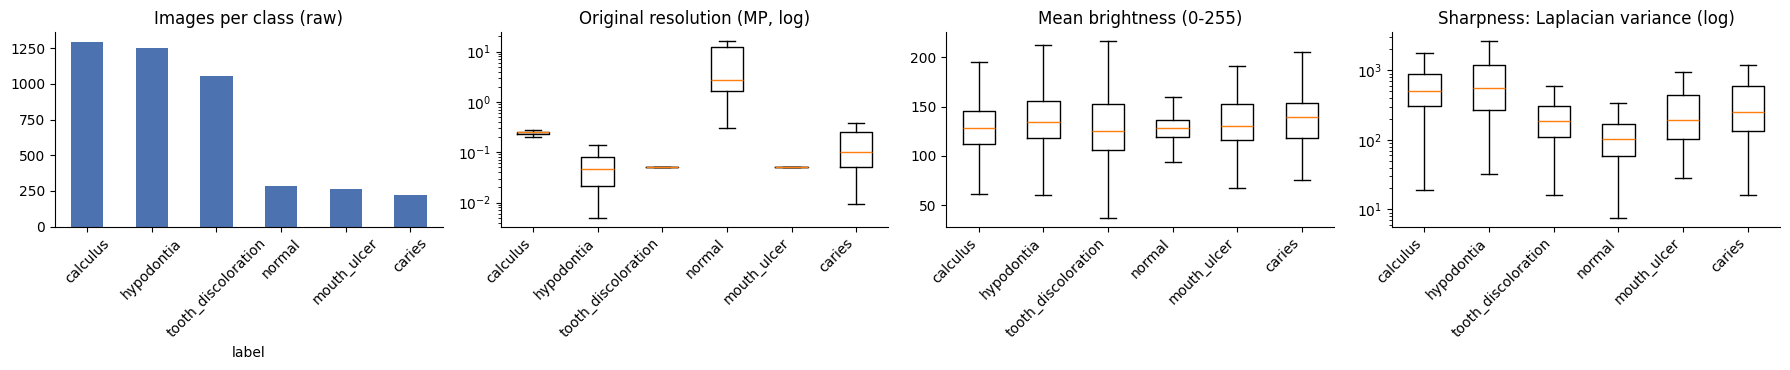

,median_MP,median_brightness,median_sharpness
label,,,
calculus,0.25,128.23,509.88
caries,0.10,139.91,249.77
hypodontia,0.05,133.88,560.73
mouth_ulcer,0.05,130.08,192.79
normal,2.77,128.53,101.92
tooth_discoloration,0.05,125.25,188.36


,JPG,jpeg,jpg
label,,,
calculus,0,0,1296
caries,0,0,219
hypodontia,909,0,342
mouth_ulcer,0,0,265
normal,0,0,286
tooth_discoloration,0,875,183


In [5]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
order = kag.label.value_counts().index
kag.label.value_counts().plot.bar(ax=ax[0], color="#4C72B0"); ax[0].set_title("Images per class (raw)")
for a, col, title, log in [(ax[1], "megapixels", "Original resolution (MP, log)", True),
                           (ax[2], "brightness", "Mean brightness (0-255)", False),
                           (ax[3], "sharpness", "Sharpness: Laplacian variance (log)", True)]:
    a.boxplot([kag.loc[kag.label == c, col].dropna() for c in order], showfliers=False)
    a.set_xticks(range(1, len(order) + 1), order, rotation=45, ha="right"); a.set_title(title)
    if log: a.set_yscale("log")
ax[0].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(FIGS / "eda_class_quality.png", bbox_inches="tight"); plt.show()

display(kag.groupby("label").agg(median_MP=("megapixels", "median"), median_brightness=("brightness", "median"),
                                 median_sharpness=("sharpness", "median")).round(2))
display(pd.crosstab(kag.label, kag.file_ext).rename_axis(None, axis=1))

**Reading the plots**
- **Normal** images are phone photos at several megapixels; every other class is mostly web-sized (around 0.25 MP). A model given raw resolution, sharpness or JPEG artefacts could separate Normal without looking at teeth. Caching everything at ≤384 px and adding blur/JPEG augmentation removes most of this signal; section 8 tests whether any remains.
- **Tooth discoloration** has ~875 `.jpeg` files named `Tooth_Discoloration_0_<n>.jpeg`. This is the naming pattern of Keras `ImageDataGenerator`, so the class was **augmented before it was published**. The duplicate scan below confirms the same for Calculus and Hypodontia.

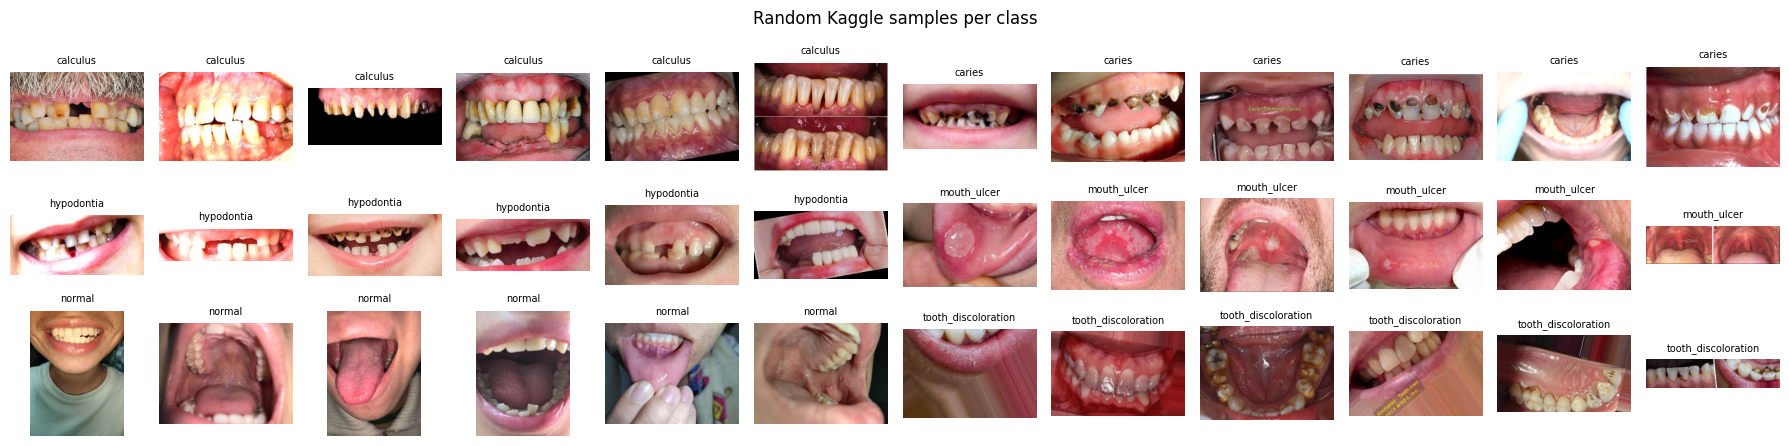

In [6]:
def show_grid(paths, titles=None, ncol=8, size=2.0, suptitle=None):
    n = len(paths); nrow = max(1, math.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size))
    for i, a in enumerate(np.atleast_1d(axes).flat):
        a.axis("off")
        if i < n:
            a.imshow(Image.open(paths[i]).convert("RGB"))
            if titles is not None: a.set_title(titles[i], fontsize=7)
    if suptitle: fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
samp = kag[kag.ok].groupby("label").sample(n=6, random_state=0)
show_grid(samp.cache.tolist(), samp.label.tolist(), ncol=12, size=1.5, suptitle="Random Kaggle samples per class")

## 3. Duplicate and near-duplicate detection

A random split of this dataset would put augmented copies of the same photo in both train and test, which inflates test accuracy. We build a graph where two images are linked if **any** of the following holds:

1. identical bytes (MD5),
2. pHash Hamming distance ≤ 6 (re-encoded / resized / lightly recoloured copies),
3. cosine similarity ≥ 0.90 between ImageNet EfficientNet-B0 embeddings (rotated, sheared, cropped copies that pHash misses).

The thresholds were picked by inspecting pairs in similarity bands; pairs above 0.90 were almost always the same photo. Over-grouping is safe because it only makes the split stricter. **Connected components** of this graph are "photo groups", and every split below is done by group.

In [7]:
FEAT_CACHE = PROC / "embeddings_effb0.npz"


@torch.no_grad()
def embed_cached(paths, bs=64):
    # L2-normalised EfficientNet-B0 (ImageNet) features, cached on disk by file name (= md5).
    store = {}
    if FEAT_CACHE.exists():
        z = np.load(FEAT_CACHE); store = dict(zip(z["keys"].tolist(), z["emb"]))
    todo = [p for p in dict.fromkeys(paths) if Path(p).stem not in store]
    if todo:
        w = tv.models.EfficientNet_B0_Weights.IMAGENET1K_V1
        m = tv.models.efficientnet_b0(weights=w); m.classifier = nn.Identity(); m = m.to(DEVICE).eval()
        tf = w.transforms()
        for i in tqdm(range(0, len(todo), bs), desc="embedding"):
            chunk = todo[i:i + bs]
            x = torch.stack([tf(Image.open(p).convert("RGB")) for p in chunk]).to(DEVICE)
            for p, e in zip(chunk, F.normalize(m(x), dim=1).cpu().numpy()):
                store[Path(p).stem] = e.astype(np.float32)
        np.savez(FEAT_CACHE, keys=np.array(list(store)), emb=np.stack(list(store.values())))
    return np.stack([store[Path(p).stem] for p in paths])


def hamming(A, B):
    A = A.astype(np.float32); B = B.astype(np.float32)
    return A @ (1 - B).T + (1 - A) @ B.T


def dup_matrix(bits_a, emb_a, bits_b=None, emb_b=None, cos_min=None):
    bits_b = bits_a if bits_b is None else bits_b
    emb_b = emb_a if emb_b is None else emb_b
    cos_min = CFG["dup_cosine_min"] if cos_min is None else cos_min
    return (emb_a @ emb_b.T >= cos_min) | (hamming(bits_a, bits_b) <= CFG["dup_phash_max_hamming"])


okm = kag.ok.values
kag, kag_bits = kag[okm].reset_index(drop=True), kag_bits[okm]
kag_emb = embed_cached(kag.cache.tolist())

exact duplicate files                : 553
byte-identical files in >1 class      : 27 distinct images
photo groups (after near-dup merge)   : 2264 from 4276 files
groups whose copies carry >1 label    : 19 (284 files)
largest group size                    : 51


,files,unique_photos,files_in_conflicting_groups,copies_per_photo,share_raw_%,share_unique_%
label,,,,,,
calculus,1296,252,227,5.14,30.3,11.0
hypodontia,1152,482,18,2.39,26.9,21.1
tooth_discoloration,1058,864,27,1.22,24.7,37.8
normal,286,282,0,1.01,6.7,12.3
mouth_ulcer,265,220,0,1.20,6.2,9.6
caries,219,185,12,1.18,5.1,8.1


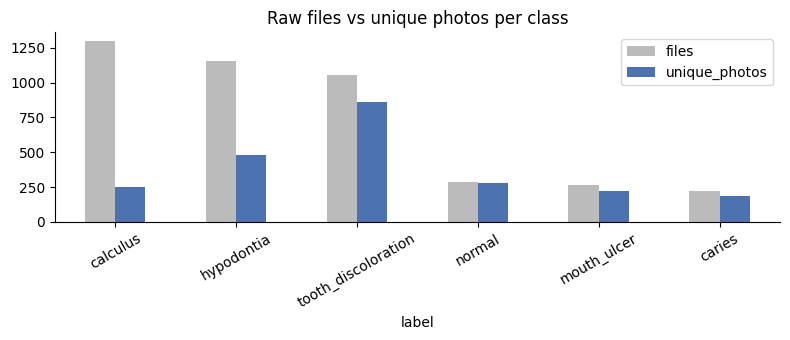

In [8]:
A_kag = dup_matrix(kag_bits, kag_emb)
n_groups, comp = connected_components(csr_matrix(A_kag), directed=False)
kag["group"] = ["k%05d" % c for c in comp]
kag["group_size"] = kag.groupby("group").path.transform("size")
labels_in_group = kag.groupby("group").label.nunique()
kag["label_conflict"] = kag.group.map(labels_in_group) > 1

exact_dup = kag.md5.duplicated(keep="first").sum()
md5_conflict = (kag.groupby("md5").label.nunique() > 1).sum()
print(f"exact duplicate files                : {exact_dup}")
print(f"byte-identical files in >1 class      : {md5_conflict} distinct images")
print(f"photo groups (after near-dup merge)   : {n_groups} from {len(kag)} files")
print(f"groups whose copies carry >1 label    : {(labels_in_group > 1).sum()} ({kag.label_conflict.sum()} files)")
print(f"largest group size                    : {kag.group_size.max()}")

summary = kag.groupby("label").agg(files=("path", "size"), unique_photos=("group", "nunique"),
                                   files_in_conflicting_groups=("label_conflict", "sum"))
summary["copies_per_photo"] = (summary.files / summary.unique_photos).round(2)
summary["share_raw_%"] = (100 * summary.files / summary.files.sum()).round(1)
summary["share_unique_%"] = (100 * summary.unique_photos / summary.unique_photos.sum()).round(1)
display(summary.sort_values("files", ascending=False))

ax = summary.sort_values("files", ascending=False)[["files", "unique_photos"]].plot.bar(figsize=(8, 3.5), color=["#bbbbbb", "#4C72B0"])
ax.set_title("Raw files vs unique photos per class"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(FIGS / "raw_vs_unique.png", bbox_inches="tight"); plt.show()

**What this changes.** The brief describes the imbalance as Caries 219 vs Calculus 1,296. After de-duplication, **Calculus has only ~255 distinct photos** (about five augmented copies each), and the largest class is really Tooth discoloration. A sampler that balances by file count would still over-weight a handful of Calculus photos, so the sampler in section 5 balances by **class and photo group**.

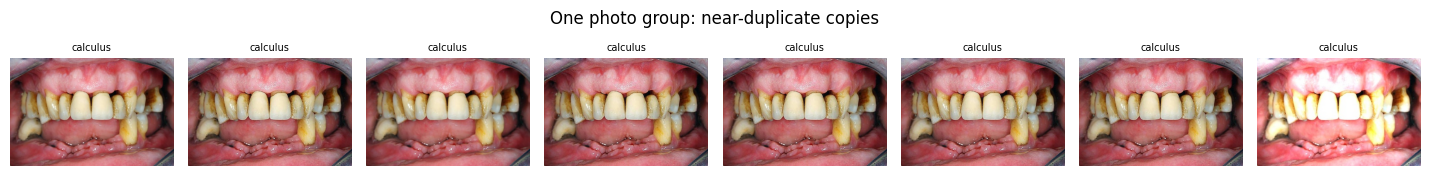

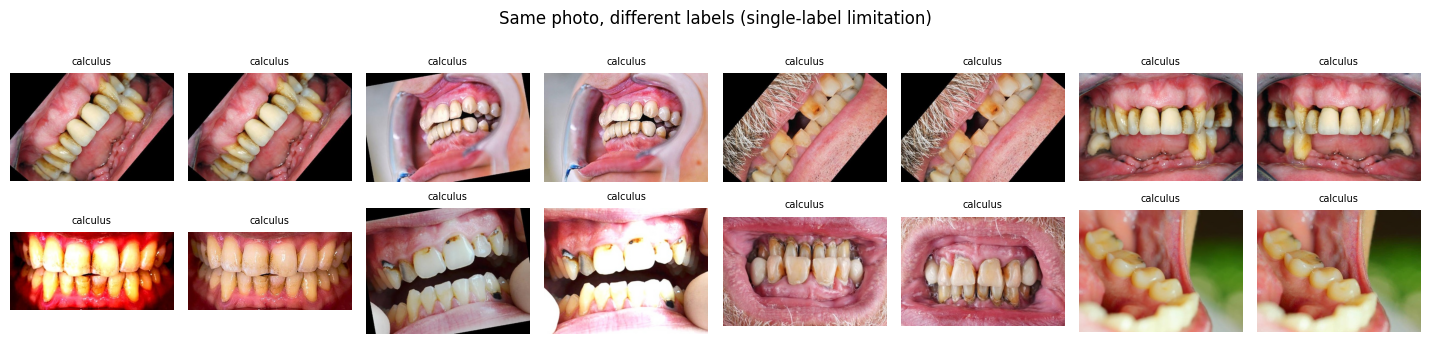

groups
calculus caries hypodontia tooth_discoloration        
True     True   False      False                     8
         False  False      True                      5
                True       False                     4
                           True                      2

In [9]:
# Examples: one multi-copy group, and groups where the same photo carries different labels
big = kag[kag.group == kag.loc[kag.group_size.idxmax(), "group"]].head(8)
show_grid(big.cache.tolist(), big.label.tolist(), ncol=8, size=1.8, suptitle="One photo group: near-duplicate copies")

conf = kag[kag.label_conflict].sort_values("group")
ex = conf.groupby("group").head(2).head(16)
show_grid(ex.cache.tolist(), ex.label.tolist(), ncol=8, size=1.8, suptitle="Same photo, different labels (single-label limitation)")
display(pd.crosstab(conf.group, conf.label).astype(bool).value_counts().rename("groups").to_frame().head(10))

**Label conflicts.** The same photo filed under two classes, usually Calculus with Hypodontia or Tooth discoloration, is the brief's *one label per image* problem in concrete form: the mouth really shows both. These groups go to **training only**, where the model sees both labels and learns to split probability between them. They are never in val/test, where a single "right answer" would be arbitrary. The app should show the **top two** conditions, not only the argmax.

### How much a naive random split would leak

In [10]:
rng = np.random.default_rng(CFG["seed"])
perm = rng.permutation(len(kag)); n_te = int(0.15 * len(kag))
te_idx, tr_idx = perm[:n_te], perm[2 * n_te:]
leak = A_kag[np.ix_(te_idx, tr_idx)].any(1)
print(f"Random 70/15/15 split: {leak.mean():.1%} of test images would have a copy of the same photo in train.")
print(kag.iloc[te_idx].assign(leak=leak).groupby("label").leak.mean().map("{:.0%}".format).to_string())

Random 70/15/15 split: 53.2% of test images would have a copy of the same photo in train.
label
calculus               90%
caries                 16%
hypodontia             69%
mouth_ulcer            27%
normal                  0%
tooth_discoloration    24%


## 4. Group-aware train / val / test split (Kaggle)

- `StratifiedGroupKFold` keeps every photo group in one split while keeping the class mix similar (≈70/15/15).
- Label-conflict groups are forced into train.
- Val and test keep **one representative image per group** (the largest, preferring originals over `.jpeg` augmentation outputs). The other copies of a val/test photo are dropped entirely. Moving them to train would leak.
- The split is written to `manifests/classifier_split.csv` (relative paths + MD5), so teammates can rebuild it without committing images.

In [11]:
def _fold_of_size(df, label_col, k, seed):
    # StratifiedGroupKFold can leave a fold nearly empty when one class is rare, so take the fold closest to 1/k.
    folds = list(StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed).split(df, df[label_col], df["group"]))
    return min(folds, key=lambda f: abs(len(f[1]) - len(df) / k))


def group_split(df, label_col, test_frac, val_frac, seed):
    # Returns a Series of 'train'/'val'/'test' using two rounds of StratifiedGroupKFold.
    split = pd.Series("train", index=df.index)
    k_test = max(2, round(1 / test_frac))
    rest, te = _fold_of_size(df, label_col, k_test, seed)
    split.iloc[te] = "test"
    df_rest = df.iloc[rest]
    k_val = max(2, round((1 - 1 / k_test) / val_frac))
    _, va = _fold_of_size(df_rest, label_col, k_val, seed + 1)
    split.loc[df_rest.index[va]] = "val"
    return split


def pick_representatives(df):
    # One image per group: prefer non-augmented originals, then the largest original resolution.
    key = df.assign(_aug=df.file_ext.str.lower().eq("jpeg").astype(int),
                    _area=-(df.orig_w * df.orig_h))
    keep = key.sort_values(["group", "_aug", "_area"]).groupby("group").head(1).index
    return df.index.isin(keep)


clean = kag[~kag.label_conflict]
kag["split"] = "train"
kag.loc[clean.index, "split"] = group_split(clean, "label", CFG["test_frac"], CFG["val_frac"], CFG["seed"])
kag["eval_rep"] = False
for s in ["val", "test"]:
    m = kag.split == s
    kag.loc[m, "eval_rep"] = pick_representatives(kag[m])
kag["use"] = (kag.split == "train") | kag.eval_rep          # non-representative val/test copies are dropped

# sanity checks: no group straddles splits; no train image near-duplicates a test image
assert kag.groupby("group").split.nunique().max() == 1
tr_m, te_m = (kag.split == "train").values, (kag.split == "test").values
assert not A_kag[np.ix_(te_m, tr_m)].any(), "leak between test and train"

tab = pd.crosstab(kag[kag.use].label, kag[kag.use].split)[["train", "val", "test"]]
tab["train_unique_photos"] = kag[kag.split == "train"].groupby("label").group.nunique()
display(tab)

split,train,val,test,train_unique_photos
label,,,,
calculus,1017,37,33,182
caries,160,25,25,135
hypodontia,795,67,67,348
mouth_ulcer,188,32,33,155
normal,206,37,42,203
tooth_discoloration,764,122,121,621


## 5. External caries data (Zenodo, DentalAI) and external check sets (Mendeley)

Caries is the smallest class and the one with the biggest cost consequence: a missed lesion can become a S\$872 to S\$1,400 root canal. Two independent datasets have caries annotations:

* **Zenodo benchmark.** An image is *caries* if its YOLO file has at least one `d`/`D` box, otherwise *no caries*. Patient IDs in the file names (`anonymous_003_007_392_01_…`) group the five views of the same mouth.
* **DentalAI.** An image is *caries* if it has a `Caries` or `Cavity` polygon. Roboflow file names (`1000_jpg.rf.<hash>.jpg`) group augmented exports of the same source photo.
* **Mendeley.** Unlabelled for our classes. It is treated as caries-free, following the team's folder name; the photos are clinical views with tartar and stains but no obvious cavities. A random sample, split half into val and half into test, serves only as a "should rarely say caries" check.

Two safeguards:
1. Any external image that near-duplicates a Kaggle image is **removed**. Several DentalAI photos are the same images as Kaggle Caries/Calculus photos.
2. These images become *caries* in a 6-class problem even if the mouth also shows tartar or stains (single-label noise), and they come from different cameras. That creates a risk that the model learns "Zenodo-looking photo ⇒ caries". The **no-caries** images from the same two sources are held back as a direct test of that shortcut.

In [12]:
ext_rows = []
ZB = RAW / "zenodo" / "Benchmarking Dataset"
for lbl in sorted(ZB.glob("*/yolo/*.txt")):                     # train/valid/test (the nested copy is identical)
    imgs = list((lbl.parent.parent / "images").glob(lbl.stem + ".*"))
    if not imgs: continue
    has_box = any(l.strip() for l in open(lbl))
    m = re.match(r"anonymous_(\d+_\d+_\d+_\d+)", lbl.stem)
    ext_rows.append(dict(source="zenodo", path=str(imgs[0]), binary="caries" if has_box else "no_caries",
                         patient="z" + (m.group(1) if m else lbl.stem)))

for ann in sorted((RAW / "dentalai").glob("*/ann/*.json")):
    img = ann.parent.parent / "img" / ann.stem                   # '<name>.jpg.json' -> '<name>.jpg'
    if not img.exists(): continue
    titles = {o["classTitle"] for o in json.load(open(ann))["objects"]}
    base = re.match(r"(.+?)_(jpe?g|png)\.rf\.", img.name, re.I)
    ext_rows.append(dict(source="dentalai", path=str(img), binary="caries" if titles & {"Caries", "Cavity"} else "no_caries",
                         patient="d" + (base.group(1) if base else img.stem)))

men = sorted(glob.glob(str(RAW / "mendeley_noncaries" / "**" / "*.jpg"), recursive=True))
for p in random.Random(CFG["seed"]).sample(men, min(CFG["mendeley_sample"], len(men))):
    ext_rows.append(dict(source="mendeley", path=p, binary="no_caries", patient="m" + Path(p).stem))

ext, ext_bits = index_images(pd.DataFrame(ext_rows), "external")
okm = (ext.ok & ~ext.md5.duplicated()).values
ext, ext_bits = ext[okm].reset_index(drop=True), ext_bits[okm]
ext_emb = embed_cached(ext.cache.tolist())

# 1) remove cross-dataset duplicates of Kaggle photos
overlap = dup_matrix(ext_bits, ext_emb, kag_bits, kag_emb).any(1)
print("external images that duplicate a Kaggle photo (removed):", ext[overlap].source.value_counts().to_dict())
keep = ~overlap
ext, ext_bits, ext_emb = ext[keep].reset_index(drop=True), ext_bits[keep], ext_emb[keep]

# 2) group by near-duplicate OR same patient / same source photo.
#    Stricter cosine here: at 0.90, retractor photos of *different* patients chain into one 500+ image group.
A_ext = dup_matrix(ext_bits, ext_emb, cos_min=CFG["ext_dup_cosine_min"])
pid = ext.patient.astype("category").cat.codes.values
A_ext |= pid[:, None] == pid[None, :]
_, comp = connected_components(csr_matrix(A_ext), directed=False)
ext["group"] = ["e%05d" % c for c in comp]
ext["file_ext"] = ext.path.str.extract(r"\.(\w+)$")[0]

# 3) split per source. Mendeley is evaluation-only: half of its groups go to val (selection guardrail), half to test
ext["split"] = "test"
for src in ["zenodo", "dentalai"]:
    m = ext.source == src
    ext.loc[m, "split"] = group_split(ext[m], "binary", 0.15, 0.15, CFG["seed"])
men_groups = np.random.default_rng(CFG["seed"]).permutation(ext.loc[ext.source == "mendeley", "group"].unique())
ext.loc[(ext.source == "mendeley") & ext.group.isin(men_groups[: len(men_groups) // 2]), "split"] = "val"
ext["eval_rep"] = False
for s in ["val", "test"]:
    m = ext.split == s
    ext.loc[m, "eval_rep"] = pick_representatives(ext[m])

display(pd.crosstab([ext.source, ext.binary], ext.split)[["train", "val", "test"]])


external:   0%|          | 0/5322 [00:00<?, ?it/s]


external:   1%|          | 55/5322 [00:00<00:09, 548.52it/s]


external:   2%|▏         | 120/5322 [00:00<00:08, 607.38it/s]


external:   4%|▎         | 189/5322 [00:00<00:08, 638.64it/s]


external:   5%|▍         | 253/5322 [00:00<00:08, 606.66it/s]


external:   6%|▌         | 314/5322 [00:00<00:09, 539.65it/s]

... (74 outputs left out)


external:  99%|█████████▊| 5250/5322 [00:08<00:00, 797.73it/s]


external: 100%|██████████| 5322/5322 [00:08<00:00, 611.14it/s]

external images that duplicate a Kaggle photo (removed): {'dentalai': 50}


split               train  val  test
source   binary                     
dentalai caries      1040  203   201
         no_caries    707  147   147
mendeley no_caries      0  300   299
zenodo   caries      1549  304   311
         no_caries     42   15     6

external caries photos added to training in experiment C: {'dentalai': 200, 'zenodo': 200}


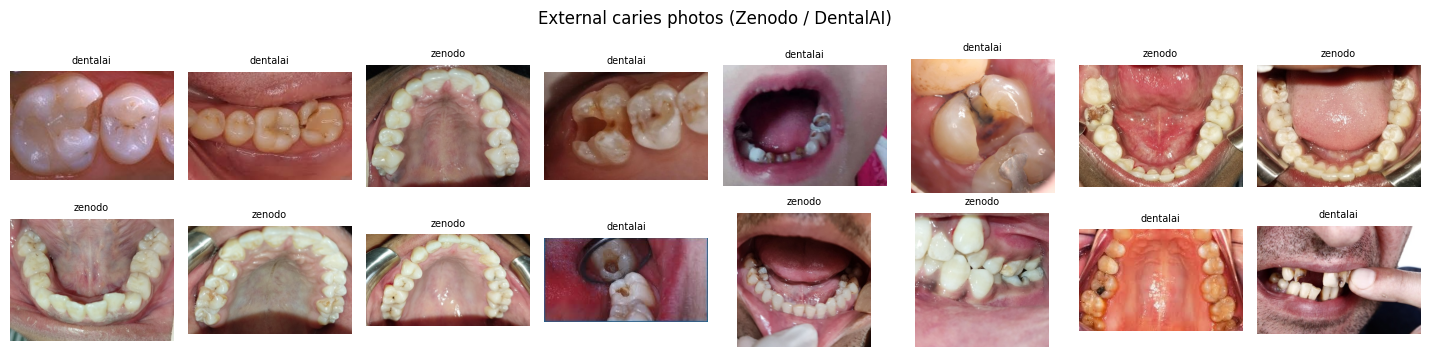

In [13]:
# Capped set of external caries photos for experiment C: one image per group, balanced across both sources
ext_train_caries = (ext[(ext.split == "train") & (ext.binary == "caries")]
                    .groupby("group").head(1)
                    .sample(frac=1, random_state=CFG["seed"])
                    .groupby("source").head(CFG["ext_caries_train_per_source"]))
ext_train_caries = ext_train_caries.assign(label="caries")
print("external caries photos added to training in experiment C:", ext_train_caries.source.value_counts().to_dict())

ext_val = ext[(ext.split == "val") & ext.eval_rep]
ext_test = ext[(ext.split == "test") & ext.eval_rep]
show_grid(ext_train_caries.sample(16, random_state=1).cache.tolist(), ext_train_caries.sample(16, random_state=1).source.tolist(),
          ncol=8, size=1.8, suptitle="External caries photos (Zenodo / DentalAI)")

In [14]:
# Persist the split so it is reproducible without sharing images
man = pd.concat([
    kag.assign(dataset_label=kag.label)[["source", "path", "md5", "label", "group", "split", "eval_rep", "label_conflict", "use"]],
    ext.assign(label=np.where(ext.binary == "caries", "caries", ""), label_conflict=False,
               use=ext.eval_rep | ext.md5.isin(ext_train_caries.md5))[
        ["source", "path", "md5", "label", "binary", "group", "split", "eval_rep", "label_conflict", "use"]],
], ignore_index=True)
man["path"] = man.path.map(lambda p: os.path.relpath(p, ROOT).replace(os.sep, "/"))
man.to_csv(MANIFESTS / "classifier_split.csv", index=False)
print("wrote", MANIFESTS / "classifier_split.csv", len(man), "rows")

wrote C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\manifests\classifier_split.csv 9547 rows


## 6. Training setup

* **Backbone.** ConvNeXt-Tiny, ImageNet-pretrained (torchvision), fully fine-tuned. A strong transfer learner for ~4k images, and small enough for CPU inference in the app.
* **Input.** The whole image is resized to 224×224 (squash, no centre-crop) so lesions near the edge, such as ulcers on the lip, are not cut off.
* **Augmentation (B, C).** Random resized crops, small rotations, flips, brightness/contrast jitter with a deliberately tiny hue jitter (colour is diagnostic for discoloration and calculus), Gaussian blur and JPEG re-compression to mimic poor phone photos.
* **Balancing (B, C).** `WeightedRandomSampler` with weight = 1 / (#groups in class × #copies in group): every class is drawn equally often, and within a class every *photo* (not every file) is equally likely.
* **Loss.** Cross-entropy with label smoothing 0.1 (B, C). The labels are noisy (single-label, multi-condition mouths), so the model should not be pushed to 100% confidence.
* **Optimiser.** AdamW, lr 1e-4, cosine decay with 1 warm-up epoch, bf16 autocast. Early stopping and checkpoint choice on the **validation score** (below), patience 6.

### Experiments (ablation)

| ID | Data | Sampler | Augmentation | Purpose |
|---|---|---|---|---|
| A | Kaggle | plain shuffle | flip only | Naive baseline: what imbalance and duplicates do |
| B | Kaggle | class + group balanced | strong | Addresses imbalance, duplicates and photo-quality variation |
| C | Kaggle + capped external caries | class + group balanced | strong | Can independent caries photos improve caries recall without a source shortcut? |

**Selection rule (fixed before training).** Patients will upload phone photos, not curated web images, so the validation score is the **mean of macro-F1 on the clean val set and on a "phone-quality" copy of it**. In that copy each image is either downscaled to 160 px, darkened, blurred or heavily JPEG-compressed. Selection then works in three steps:
1. **Guardrail.** A run is eligible only if it calls at most 15% of external *caries-free* val photos (Zenodo, DentalAI, Mendeley) "caries". A screening app that cries wolf on every clinical-looking photo would erode trust and send people for unneeded fillings.
2. The eligible run with the highest score wins.
3. If two runs are within 0.01, the one with higher external-val caries AUROC wins.

The test set is used once, after selection.

In [15]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
S = CFG["img_size"]


def make_tf(kind):
    norm = [v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)]
    if kind == "eval":
        return v2.Compose([v2.ToImage(), v2.Resize((S, S), antialias=True), *norm])
    if kind == "light":
        return v2.Compose([v2.ToImage(), v2.Resize((S, S), antialias=True), v2.RandomHorizontalFlip(), *norm])
    return v2.Compose([
        v2.ToImage(),
        v2.RandomResizedCrop(S, scale=(0.5, 1.0), ratio=(0.5, 2.0), antialias=True),
        v2.RandomHorizontalFlip(),
        v2.RandomApply([v2.RandomRotation(15)], p=0.5),
        v2.RandomApply([v2.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.15, hue=0.02)], p=0.8),
        v2.RandomApply([v2.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.2),
        v2.RandomApply([v2.JPEG((30, 90))], p=0.3),
        *norm])


class ImageDS(torch.utils.data.Dataset):
    def __init__(self, paths, labels, tf, degrade=None):
        self.paths, self.labels, self.tf, self.degrade = list(paths), list(labels), tf, degrade
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        im = Image.open(self.paths[i]).convert("RGB")
        fn = self.degrade[i] if isinstance(self.degrade, (list, tuple)) else self.degrade
        if fn is not None: im = fn(im)
        return self.tf(im), self.labels[i]


def loader(df, tf, shuffle=False, sampler=None, degrade=None, bs=None):
    labels = df.label.map(CLS2ID).fillna(-1).astype(int).values if "label" in df else np.full(len(df), -1)
    ds = ImageDS(df.cache.values, labels, tf, degrade)
    # num_workers=0: notebook-defined Dataset classes cannot be pickled to worker processes on Windows.
    # The cache images are small, so decoding stays fast.
    return torch.utils.data.DataLoader(ds, batch_size=bs or CFG["batch_size"], shuffle=shuffle and sampler is None,
                                       sampler=sampler, num_workers=0, pin_memory=DEVICE.type == "cuda")


def jpeg_roundtrip(im, q):
    b = io.BytesIO(); im.save(b, "JPEG", quality=q); b.seek(0); return Image.open(b).convert("RGB")


def lowres(im):   # web-thumbnail quality
    w, h = im.size; s = 160 / max(w, h)
    return jpeg_roundtrip(im.resize((max(1, int(w * s)), max(1, int(h * s))), Image.BILINEAR), 60)


DEGRADATIONS = {
    "original": None,
    "low-res 160px + JPEG60": lowres,
    "dark (x0.5)": lambda im: ImageEnhance.Brightness(im).enhance(0.5),
    "bright (x1.6)": lambda im: ImageEnhance.Brightness(im).enhance(1.6),
    "blur (r=2)": lambda im: im.filter(ImageFilter.GaussianBlur(2)),
    "JPEG q=20": lambda im: jpeg_roundtrip(im, 20),
}
# "Phone-quality" validation copy: each val image gets one degradation, cycling through these four
VAL_DEGRADE_CYCLE = [DEGRADATIONS[k] for k in ["low-res 160px + JPEG60", "dark (x0.5)", "blur (r=2)", "JPEG q=20"]]


def val_degrade_list(n):
    return [VAL_DEGRADE_CYCLE[i % len(VAL_DEGRADE_CYCLE)] for i in range(n)]


def balanced_sampler(df):
    copies = df.groupby(["label", "group"]).path.transform("size")
    groups_in_class = df.groupby("label").group.transform("nunique")
    w = 1.0 / (copies * groups_in_class)
    return torch.utils.data.WeightedRandomSampler(torch.tensor(w.values, dtype=torch.double), num_samples=len(df), replacement=True)


def build_model(name=CFG["backbone"], n=NUM_CLASSES, pretrained=True):
    if name == "convnext_tiny":
        m = tv.models.convnext_tiny(weights=tv.models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, n)
    elif name == "efficientnet_b0":
        m = tv.models.efficientnet_b0(weights=tv.models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n)
    elif name == "resnet50":
        m = tv.models.resnet50(weights=tv.models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, n)
    else:
        raise ValueError(name)
    return m


def cam_layer(model):
    return model.layer4 if hasattr(model, "layer4") else model.features[-1]


@torch.no_grad()
def predict_logits(model, dl):
    model.eval(); out, ys = [], []
    for x, y in dl:
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
            out.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
        ys.append(y)
    return torch.cat(out), torch.cat(ys).numpy()


def cls_metrics(y, logits):
    pred = logits.argmax(1).numpy()
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=range(NUM_CLASSES), zero_division=0)
    return dict(acc=accuracy_score(y, pred), bal_acc=balanced_accuracy_score(y, pred),
                macro_f1=f1_score(y, pred, average="macro", labels=range(NUM_CLASSES), zero_division=0),
                **{f"recall_{c}": r[i] for i, c in enumerate(CLASSES)},
                **{f"f1_{c}": f[i] for i, c in enumerate(CLASSES)})


def caries_metrics(df, logits, prefix=""):
    # Caries vs not-caries on external data: AUROC of P(caries) and argmax hit / false-alarm rates per source.
    prob = logits.softmax(1)[:, CARIES].numpy(); pred = logits.argmax(1).numpy()
    y = (df.binary.values == "caries").astype(int)
    out = {f"{prefix}caries_auroc": roc_auc_score(y, prob) if 0 < y.sum() < len(y) else np.nan,
           f"{prefix}caries_recall": (pred[y == 1] == CARIES).mean() if y.sum() else np.nan}
    for src in ["zenodo", "dentalai", "mendeley"]:
        m = (df.source.values == src) & (y == 0)
        if m.any(): out[f"{prefix}false_caries_{src}"] = (pred[m] == CARIES).mean()
    out[f"{prefix}false_caries_all"] = (pred[y == 0] == CARIES).mean() if (y == 0).any() else np.nan
    return out

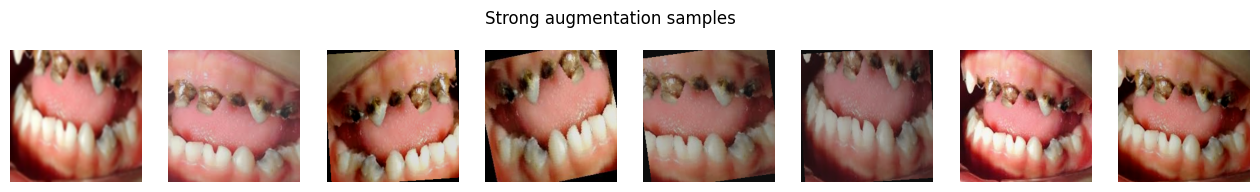

In [16]:
# Quick check of the augmentation pipeline: one training image under the strong transform
tf_s = make_tf("strong")
ex_path = kag[(kag.split == "train") & (kag.label == "caries")].cache.iloc[0]
imgs = [tf_s(Image.open(ex_path).convert("RGB")) for _ in range(8)]
fig, axes = plt.subplots(1, 8, figsize=(16, 2.2))
for a, t in zip(axes, imgs):
    a.imshow((t.permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1)); a.axis("off")
fig.suptitle("Strong augmentation samples"); plt.show()

In [17]:
def train_experiment(name, train_df, aug, balanced, label_smoothing, val_df, ext_val_df):
    seed_everything()
    model = build_model().to(DEVICE)
    dl_tr = loader(train_df, make_tf(aug), shuffle=True, sampler=balanced_sampler(train_df) if balanced else None)
    dl_va = loader(val_df, make_tf("eval"))
    dl_vd = loader(val_df, make_tf("eval"), degrade=val_degrade_list(len(val_df)))
    dl_ev = loader(ext_val_df, make_tf("eval"))
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    steps = CFG["epochs"] * len(dl_tr); warm = CFG["warmup_epochs"] * len(dl_tr)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda" and AMP_DTYPE == torch.float16)   # only needed for fp16

    best, best_state, hist, bad = -1, None, [], 0
    for ep in range(1, CFG["epochs"] + 1):
        model.train(); t0 = time.time(); tot, n = 0.0, 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda"):
                loss = crit(model(x), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item() * len(y); n += len(y)
        lv, yv = predict_logits(model, dl_va); ld, _ = predict_logits(model, dl_vd)
        mv = cls_metrics(yv, lv); mv["val_loss"] = F.cross_entropy(lv, torch.tensor(yv)).item()
        mv["deg_macro_f1"] = cls_metrics(yv, ld)["macro_f1"]
        mv["score"] = 0.5 * (mv["macro_f1"] + mv["deg_macro_f1"])
        hist.append(dict(epoch=ep, train_loss=tot / n, **mv, secs=time.time() - t0))
        print(f"{name} ep{ep:02d} train_loss {tot/n:.3f} | val_loss {mv['val_loss']:.3f} acc {mv['acc']:.3f} "
              f"bal_acc {mv['bal_acc']:.3f} macro_f1 {mv['macro_f1']:.3f} degraded_f1 {mv['deg_macro_f1']:.3f} "
              f"caries_rec {mv['recall_caries']:.2f} ({time.time()-t0:.0f}s)")
        if mv["score"] > best:
            best, bad = mv["score"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print("early stop"); break
    model.load_state_dict(best_state)
    torch.save({"state_dict": best_state, "backbone": CFG["backbone"], "classes": CLASSES}, WEIGHTS / f"exp_{name}.pt")
    lv, yv = predict_logits(model, dl_va); ld, _ = predict_logits(model, dl_vd); le, _ = predict_logits(model, dl_ev)
    h = pd.DataFrame(hist)
    summary = dict(experiment=name, best_epoch=int(h.score.idxmax()) + 1,
                   **{f"val_{k}": v for k, v in cls_metrics(yv, lv).items()},
                   val_degraded_macro_f1=cls_metrics(yv, ld)["macro_f1"],
                   **caries_metrics(ext_val_df, le, "extval_"))
    summary["val_score"] = 0.5 * (summary["val_macro_f1"] + summary["val_degraded_macro_f1"])
    return model, pd.DataFrame(hist), summary

## 7. Train the three experiments

Roughly 5 to 10 minutes per experiment on an RTX-class GPU. Each experiment's best checkpoint is saved to `models/classifier/weights/Daniel/exp_<ID>.pt`.

In [18]:
train_k = kag[(kag.split == "train")]
val_k = kag[(kag.split == "val") & kag.eval_rep]
test_k = kag[(kag.split == "test") & kag.eval_rep]
train_c = pd.concat([train_k, ext_train_caries], ignore_index=True)
print(f"train files: Kaggle {len(train_k)}, Kaggle+ext {len(train_c)} | val {len(val_k)} | test {len(test_k)} | ext val {len(ext_val)} | ext test {len(ext_test)}")

EXPERIMENTS = {
    "A_baseline": dict(train_df=train_k, aug="light", balanced=False, label_smoothing=0.0),
    "B_balanced_aug": dict(train_df=train_k, aug="strong", balanced=True, label_smoothing=0.1),
    "C_plus_ext_caries": dict(train_df=train_c, aug="strong", balanced=True, label_smoothing=0.1),
}
models, histories, summaries = {}, {}, []
for name, kw in EXPERIMENTS.items():
    models[name], histories[name], s = train_experiment(name, val_df=val_k, ext_val_df=ext_val, **kw)
    summaries.append(s)
    models[name].cpu(); torch.cuda.empty_cache()

train files: Kaggle 3130, Kaggle+ext 3530 | val 320 | test 321 | ext val 900 | ext test 897


A_baseline ep01 train_loss 0.844 | val_loss 0.314 acc 0.897 bal_acc 0.838 macro_f1 0.843 degraded_f1 0.706 caries_rec 0.36 (31s)


A_baseline ep02 train_loss 0.157 | val_loss 0.239 acc 0.909 bal_acc 0.903 macro_f1 0.886 degraded_f1 0.814 caries_rec 0.80 (10s)


A_baseline ep03 train_loss 0.078 | val_loss 0.189 acc 0.928 bal_acc 0.907 macro_f1 0.905 degraded_f1 0.854 caries_rec 0.68 (10s)


A_baseline ep04 train_loss 0.056 | val_loss 0.280 acc 0.906 bal_acc 0.854 macro_f1 0.850 degraded_f1 0.759 caries_rec 0.36 (10s)


A_baseline ep05 train_loss 0.052 | val_loss 0.260 acc 0.909 bal_acc 0.894 macro_f1 0.884 degraded_f1 0.868 caries_rec 0.68 (10s)


... (37 outputs left out)

C_plus_ext_caries ep19 train_loss 0.440 | val_loss 0.197 acc 0.956 bal_acc 0.950 macro_f1 0.939 degraded_f1 0.931 caries_rec 0.84 (18s)


C_plus_ext_caries ep20 train_loss 0.437 | val_loss 0.195 acc 0.953 bal_acc 0.943 macro_f1 0.933 degraded_f1 0.923 caries_rec 0.80 (17s)


C_plus_ext_caries ep21 train_loss 0.436 | val_loss 0.193 acc 0.959 bal_acc 0.955 macro_f1 0.943 degraded_f1 0.923 caries_rec 0.84 (17s)


C_plus_ext_caries ep22 train_loss 0.439 | val_loss 0.194 acc 0.956 bal_acc 0.952 macro_f1 0.940 degraded_f1 0.919 caries_rec 0.84 (17s)
early stop


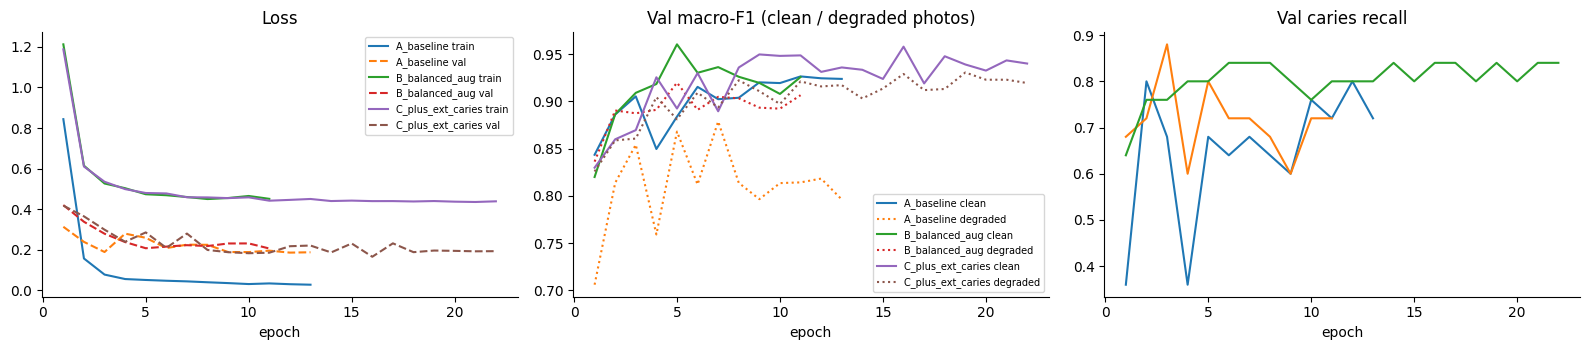

,best_epoch,val_score,val_macro_f1,val_degraded_macro_f1,val_bal_acc,val_recall_caries,val_recall_normal,val_recall_mouth_ulcer,extval_caries_auroc,extval_caries_recall,extval_false_caries_zenodo,extval_false_caries_dentalai,extval_false_caries_mendeley,extval_false_caries_all
experiment,,,,,,,,,,,,,,
A_baseline,7,0.891,0.902,0.879,0.901,0.68,0.973,0.875,0.801,0.212,0.000,0.021,0.003,0.009
B_balanced_aug,5,0.940,0.960,0.920,0.954,0.80,0.973,1.000,0.685,0.318,0.067,0.077,0.062,0.067
C_plus_ext_caries,16,0.943,0.958,0.929,0.960,0.84,0.946,1.000,0.887,0.945,0.867,0.303,0.552,0.483


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
for name, h in histories.items():
    ax[0].plot(h.epoch, h.train_loss, label=f"{name} train"); ax[0].plot(h.epoch, h.val_loss, "--", label=f"{name} val")
    ax[1].plot(h.epoch, h.macro_f1, label=f"{name} clean"); ax[1].plot(h.epoch, h.deg_macro_f1, ":", label=f"{name} degraded")
    ax[2].plot(h.epoch, h.recall_caries, label=name)
for a, t in zip(ax, ["Loss", "Val macro-F1 (clean / degraded photos)", "Val caries recall"]):
    a.set_title(t); a.set_xlabel("epoch")
ax[0].legend(fontsize=7); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / "training_curves.png", bbox_inches="tight"); plt.show()

comp = pd.DataFrame(summaries).set_index("experiment")
cols = ["best_epoch", "val_score", "val_macro_f1", "val_degraded_macro_f1", "val_bal_acc", "val_recall_caries", "val_recall_normal", "val_recall_mouth_ulcer",
        "extval_caries_auroc", "extval_caries_recall", "extval_false_caries_zenodo", "extval_false_caries_dentalai",
        "extval_false_caries_mendeley", "extval_false_caries_all"]
display(comp[[c for c in cols if c in comp]].round(3))

In [20]:
# Selection rule (declared in section 6)
# 1) guardrail: false-caries rate on external caries-free val photos <= max_ext_false_caries
eligible = comp[comp.extval_false_caries_all <= CFG["max_ext_false_caries"]]
if eligible.empty:
    print("no run passes the false-caries guardrail; falling back to the run with the fewest false alarms")
    eligible = comp.nsmallest(1, "extval_false_caries_all")
print("eligible:", list(eligible.index), "| excluded by guardrail:", sorted(set(comp.index) - set(eligible.index)))
# 2) best val score, 3) tie-break (<0.01) on external-val caries AUROC
ranked = eligible.sort_values("val_score", ascending=False)
top = ranked.iloc[0]
close = ranked[ranked.val_score >= top.val_score - 0.01]
BEST = close.extval_caries_auroc.fillna(0).idxmax()
print("selected experiment:", BEST)
model = models[BEST].to(DEVICE).eval()

eligible: ['A_baseline', 'B_balanced_aug'] | excluded by guardrail: ['C_plus_ext_caries']
selected experiment: B_balanced_aug


## 8. Evaluation on the held-out Kaggle test set

The test set is de-duplicated (one image per photo group) and shares no photo group with training. The headline metrics are **macro-F1** and **balanced accuracy**; plain accuracy is shown for reference only, because it hides poor minority-class performance. 95% confidence intervals come from 2,000 bootstrap resamples of the test images. With only ~30 to 40 unique test photos in the small classes, the intervals are wide and should be reported.

In [21]:
dl_te = loader(test_k, make_tf("eval"))
test_logits = {n: predict_logits(m.to(DEVICE), dl_te)[0] for n, m in models.items()}
y_te = test_k.label.map(CLS2ID).values
for m in models.values(): m.cpu()
model.to(DEVICE)


def bootstrap_ci(y, logits, fn, n=2000, seed=0):
    rng = np.random.default_rng(seed); pred = logits.argmax(1).numpy(); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); vals.append(fn(y[i], pred[i]))
    return np.percentile(vals, [2.5, 97.5])


rows = []
for n, lg in test_logits.items():
    mt = cls_metrics(y_te, lg)
    lo, hi = bootstrap_ci(y_te, lg, lambda a, b: f1_score(a, b, average="macro", labels=range(NUM_CLASSES), zero_division=0))
    rows.append(dict(experiment=n, test_acc=mt["acc"], test_bal_acc=mt["bal_acc"], test_macro_f1=mt["macro_f1"],
                     macro_f1_95ci=f"[{lo:.3f}, {hi:.3f}]", test_recall_caries=mt["recall_caries"], test_recall_normal=mt["recall_normal"]))
test_table = pd.DataFrame(rows).set_index("experiment")
display(test_table.round(3))
print("(All three are shown for the ablation. Selection was made on validation only.)")

logits_best = test_logits[BEST]
pred_te = logits_best.argmax(1).numpy()
print(f"\nSelected model {BEST}: per-class report on the de-duplicated test set")
print(classification_report(y_te, pred_te, target_names=CLASSES, digits=3, zero_division=0))
print("one-vs-rest macro AUROC:", round(roc_auc_score(y_te, logits_best.softmax(1).numpy(), multi_class="ovr", average="macro"), 3))

,test_acc,test_bal_acc,test_macro_f1,macro_f1_95ci,test_recall_caries,test_recall_normal
experiment,,,,,,
A_baseline,0.928,0.890,0.899,"[0.855, 0.936]",0.64,0.976
B_balanced_aug,0.944,0.919,0.921,"[0.883, 0.953]",0.76,0.952
C_plus_ext_caries,0.960,0.951,0.948,"[0.915, 0.974]",0.84,0.952


(All three are shown for the ablation. Selection was made on validation only.)

Selected model B_balanced_aug: per-class report on the de-duplicated test set
                     precision    recall  f1-score   support

           calculus      0.968     0.909     0.938        33
             caries      0.792     0.760     0.776        25
         hypodontia      0.969     0.940     0.955        67
        mouth_ulcer      0.914     0.970     0.941        33
             normal      0.930     0.952     0.941        42
tooth_discoloration      0.967     0.983     0.975       121

           accuracy                          0.944       321
          macro avg      0.923     0.919     0.921       321
       weighted avg      0.944     0.944     0.944       321

one-vs-rest macro AUROC: 0.996


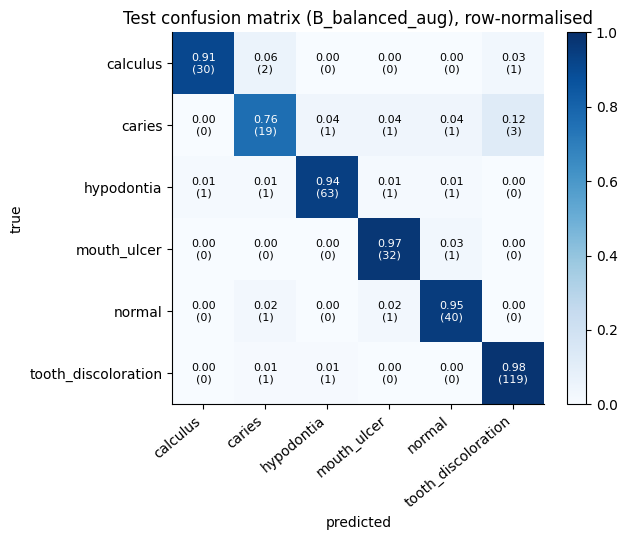

In [22]:
cm = confusion_matrix(y_te, pred_te, labels=range(NUM_CLASSES))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(NUM_CLASSES), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Test confusion matrix ({BEST}), row-normalised")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(FIGS / "confusion_matrix.png", bbox_inches="tight"); plt.show()

### 8.1 Calibration and abstention

The app turns probabilities into plain-language urgency, so a "90%" has to mean roughly 90%. We fit a single **temperature** on the validation logits, which does not change any prediction, and measure the expected calibration error (ECE) on test.

The model also needs a way to say *"I'm not sure, please see a dentist."* We choose the lowest confidence threshold (minimum 0.5) at which **validation** accuracy on accepted images reaches 95%, then report the coverage and accuracy that threshold gives on **test**.

temperature T = 0.621 | test ECE before 0.090 -> after 0.023
abstain below confidence 0.50: test coverage 98.8%, accuracy on accepted 95.0% (vs 94.4% overall); abstained images per true class:
caries    3
normal    1


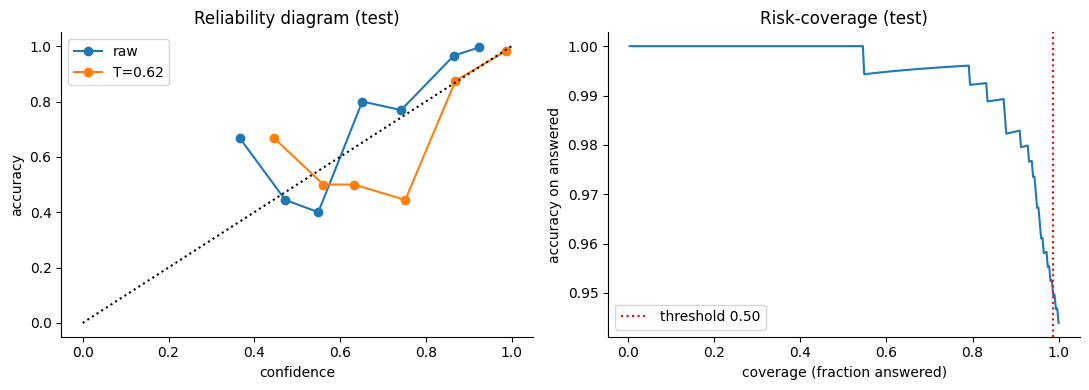

In [23]:
val_logits, y_va = predict_logits(model, loader(val_k, make_tf("eval")))


def fit_temperature(logits, y):
    t = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([t], lr=0.1, max_iter=200)
    yt = torch.tensor(y)
    def closure():
        opt.zero_grad(); l = F.cross_entropy(logits / t.exp(), yt); l.backward(); return l
    opt.step(closure)
    return float(t.exp())


def ece(probs, y, bins=15):
    conf, pred = probs.max(1); acc = (pred.numpy() == y)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf.numpy() > lo) & (conf.numpy() <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf.numpy()[m].mean())
    return e


T = fit_temperature(val_logits, y_va)
p_raw, p_cal = logits_best.softmax(1), (logits_best / T).softmax(1)
print(f"temperature T = {T:.3f} | test ECE before {ece(p_raw, y_te):.3f} -> after {ece(p_cal, y_te):.3f}")

# abstention threshold from validation
pv = (val_logits / T).softmax(1); cv, predv = pv.max(1); okv = predv.numpy() == y_va
THRESH = None
for t in np.linspace(CFG["min_abstain_conf"], 0.99, 50):
    m = cv.numpy() >= t
    if m.mean() >= 0.5 and okv[m].mean() >= CFG["target_selective_accuracy"]:
        THRESH = float(t); break
if THRESH is None:
    print("target selective accuracy not reachable at >=50% coverage; using the floor")
    THRESH = CFG["min_abstain_conf"]
ct, predt = p_cal.max(1); okt = predt.numpy() == y_te; acc_m = ct.numpy() >= THRESH
print(f"abstain below confidence {THRESH:.2f}: test coverage {acc_m.mean():.1%}, accuracy on accepted {okt[acc_m].mean():.1%} "
      f"(vs {okt.mean():.1%} overall); abstained images per true class:")
print(pd.Series(np.array(CLASSES)[y_te[~acc_m]]).value_counts().to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for p, lab in [(p_raw, "raw"), (p_cal, f"T={T:.2f}")]:
    c, pr = p.max(1); edges = np.linspace(0, 1, 11); xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (c.numpy() > lo) & (c.numpy() <= hi)
        if m.sum() >= 3: xs.append(c.numpy()[m].mean()); ys.append((pr.numpy()[m] == y_te[m]).mean())
    ax[0].plot(xs, ys, "o-", label=lab)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set(xlabel="confidence", ylabel="accuracy", title="Reliability diagram (test)"); ax[0].legend()
order_ = np.argsort(-ct.numpy()); cov = np.arange(1, len(order_) + 1) / len(order_)
ax[1].plot(cov, np.cumsum(okt[order_]) / np.arange(1, len(order_) + 1))
ax[1].axvline(acc_m.mean(), ls=":", c="r", label=f"threshold {THRESH:.2f}")
ax[1].set(xlabel="coverage (fraction answered)", ylabel="accuracy on answered", title="Risk-coverage (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIGS / "calibration_abstention.png", bbox_inches="tight"); plt.show()

### 8.2 Robustness to poor photos and the resolution shortcut

Patients will upload dark, blurry, low-resolution phone photos. We re-run the test set under controlled degradations. The **low-res** case also probes the Normal-class shortcut: if Normal recall collapses when Normal photos are reduced to web-image quality, the model was partly relying on resolution rather than anatomy.

In [24]:
rob_all = []
for n, m in models.items():
    m.to(DEVICE)
    base = None
    for dname, fn in DEGRADATIONS.items():
        lg, _ = predict_logits(m, loader(test_k, make_tf("eval"), degrade=fn))
        mt = cls_metrics(y_te, lg); pr = lg.argmax(1).numpy(); base = pr if base is None else base
        rob_all.append(dict(experiment=n, condition=dname, macro_f1=mt["macro_f1"], recall_normal=mt["recall_normal"],
                            recall_caries=mt["recall_caries"], changed_vs_original=(pr != base).mean()))
    m.cpu()
model.to(DEVICE)
rob_df = pd.DataFrame(rob_all)
print("Test macro-F1 under degraded photos")
display(rob_df.pivot(index="condition", columns="experiment", values="macro_f1").loc[list(DEGRADATIONS)].round(3))
print("Normal-class recall under degraded photos (resolution-shortcut probe)")
display(rob_df.pivot(index="condition", columns="experiment", values="recall_normal").loc[list(DEGRADATIONS)].round(3))
rob = rob_df[rob_df.experiment == BEST].drop(columns="experiment").to_dict("records")

Test macro-F1 under degraded photos


experiment,A_baseline,B_balanced_aug,C_plus_ext_caries
condition,,,
original,0.899,0.921,0.948
low-res 160px + JPEG60,0.706,0.853,0.838
dark (x0.5),0.918,0.909,0.941
bright (x1.6),0.818,0.925,0.914
blur (r=2),0.860,0.871,0.931
JPEG q=20,0.767,0.881,0.909


Normal-class recall under degraded photos (resolution-shortcut probe)


experiment,A_baseline,B_balanced_aug,C_plus_ext_caries
condition,,,
original,0.976,0.952,0.952
low-res 160px + JPEG60,0.381,0.881,0.738
dark (x0.5),0.976,0.929,0.952
bright (x1.6),0.905,0.905,0.810
blur (r=2),0.905,0.905,0.881
JPEG q=20,0.548,0.905,0.810


### 8.3 Explainability: Grad-CAM

Grad-CAM shows which pixels drove the prediction. This is useful both for the report (transparency) and for spotting shortcuts, such as a model that looks at lips, background or watermarks instead of teeth.

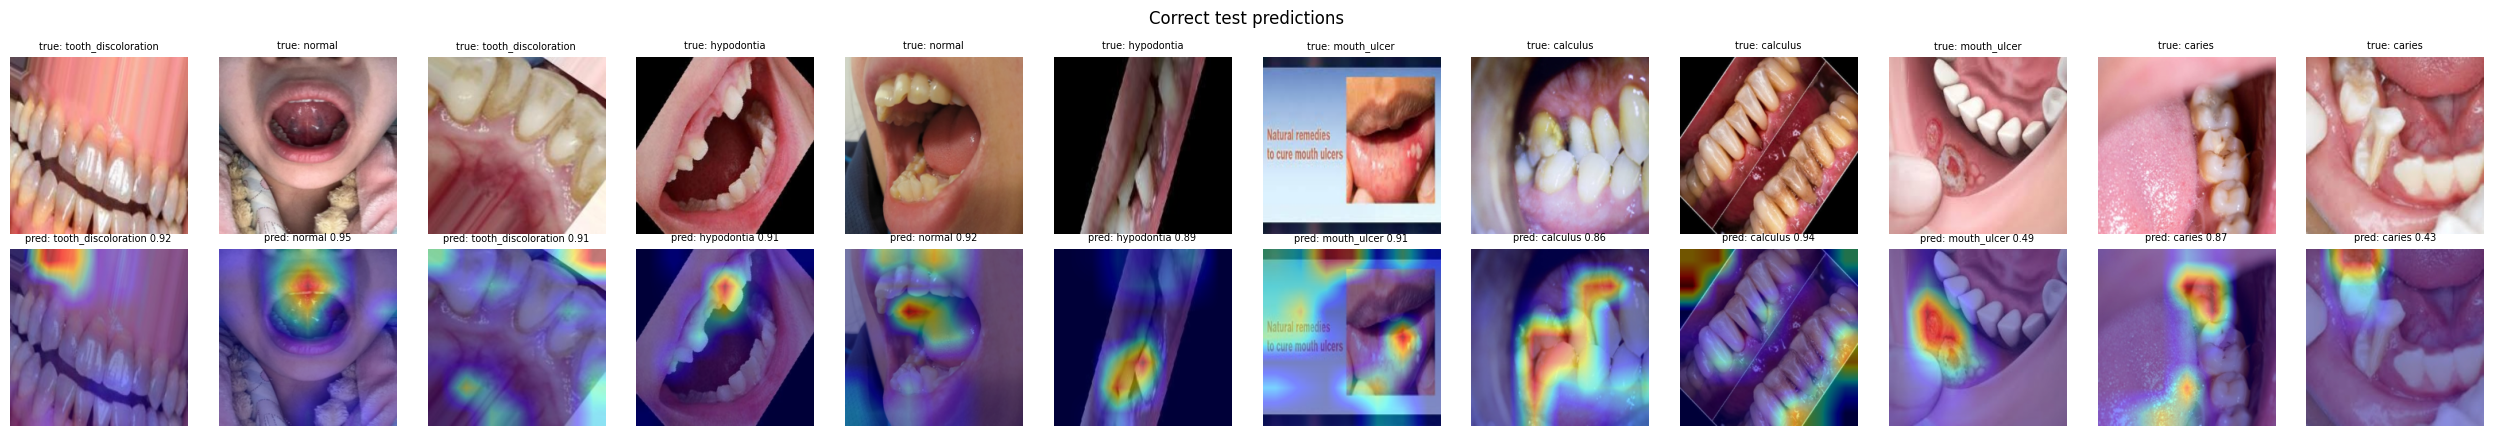

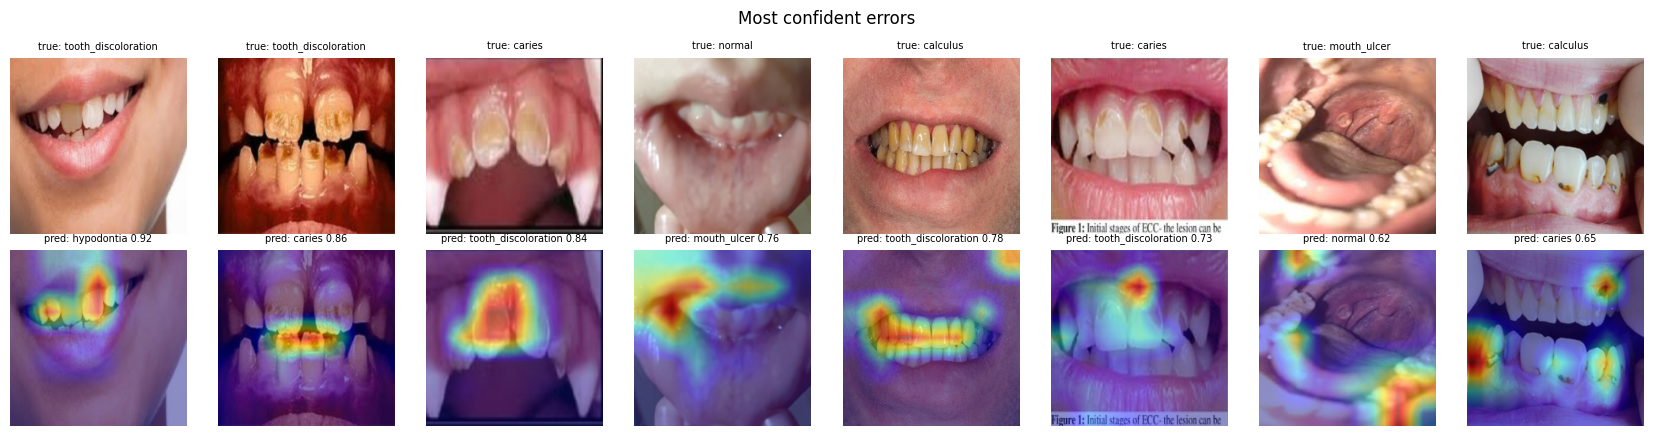

In [25]:
def gradcam(model, x, cls=None):
    store = {}
    layer = cam_layer(model)
    def fwd_hook(m, i, o):
        store["a"] = o
        o.register_hook(lambda g: store.__setitem__("g", g))
    h = layer.register_forward_hook(fwd_hook)
    model.eval(); model.zero_grad()
    logits = model(x)
    cls = logits.argmax(1) if cls is None else cls
    logits.gather(1, cls[:, None]).sum().backward()
    h.remove()
    w = store["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * store["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = (cam - cam.amin((1, 2), keepdim=True)) / (cam.amax((1, 2), keepdim=True) - cam.amin((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu(), logits.detach().softmax(1).cpu()


def show_cams(df, title, n=8):
    df = df.head(n)
    x = torch.stack([make_tf("eval")(Image.open(p).convert("RGB")) for p in df.cache]).to(DEVICE)
    cams, probs = gradcam(model.float(), x)
    fig, axes = plt.subplots(2, len(df), figsize=(2.1 * len(df), 4.4))
    axes = np.array(axes).reshape(2, -1)
    for i in range(len(df)):
        img = (x[i].cpu().permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEAN)).clamp(0, 1).numpy()
        axes[0, i].imshow(img); axes[0, i].set_title(f"true: {df.label.iloc[i]}", fontsize=7)
        axes[1, i].imshow(img); axes[1, i].imshow(cams[i], cmap="jet", alpha=0.45)
        k = probs[i].argmax().item(); axes[1, i].set_title(f"pred: {CLASSES[k]} {probs[i, k]:.2f}", fontsize=7)
        for a in axes[:, i]: a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIGS / f"gradcam_{title.split()[0].lower()}.png", bbox_inches="tight"); plt.show()


te = test_k.assign(pred=np.array(CLASSES)[pred_te], conf=p_cal.max(1).values.numpy())
show_cams(te[te.pred == te.label].sample(frac=1, random_state=0).groupby("label").head(2),
          "Correct test predictions", n=12)
wrong = te[te.pred != te.label].sort_values("conf", ascending=False)
if len(wrong):
    show_cams(wrong, "Most confident errors", n=min(8, len(wrong)))

## 9. External validation: does it generalise beyond Kaggle?

The brief notes the images are not from Singapore patients. We have no Singapore data, but we can at least test on **populations and cameras the model never trained on**. For experiments A and B, Zenodo and DentalAI are fully unseen. For C, they share a source but not a patient or photo.

* **AUROC of P(caries)** on caries vs no-caries photos (threshold-free),
* **caries recall** at the argmax,
* **false-caries rate** on caries-free photos from each source. This is the **shortcut test**: a model that learned "Zenodo look ⇒ caries" would flag Zenodo's caries-free mouths as caries.

In [26]:
dl_ext = loader(ext_test, make_tf("eval"))
ext_rows_ = []
for n, m in models.items():
    lg, _ = predict_logits(m.to(DEVICE), dl_ext); m.cpu()
    ext_rows_.append(dict(experiment=n, **caries_metrics(ext_test, lg, "exttest_")))
    if n == BEST: ext_logits_best = lg
model.to(DEVICE)
display(pd.DataFrame(ext_rows_).set_index("experiment").round(3))
print("ext test counts:", ext_test.groupby(["source", "binary"]).size().to_dict())

# What does the selected model call the (unlabelled) Mendeley clinical photos?
men_te = ext_test.source.values == "mendeley"
pd.Series(np.array(CLASSES)[ext_logits_best.argmax(1).numpy()[men_te]]).value_counts(normalize=True).round(3).rename("share of Mendeley predictions").to_frame().T

,exttest_caries_auroc,exttest_caries_recall,exttest_false_caries_zenodo,exttest_false_caries_dentalai,exttest_false_caries_mendeley,exttest_false_caries_all
experiment,,,,,,
A_baseline,0.771,0.192,0.000,0.028,0.003,0.011
B_balanced_aug,0.676,0.316,0.333,0.070,0.048,0.059
C_plus_ext_caries,0.880,0.908,1.000,0.352,0.559,0.498


ext test counts: {('dentalai', 'caries'): 193, ('dentalai', 'no_caries'): 142, ('mendeley', 'no_caries'): 290, ('zenodo', 'caries'): 266, ('zenodo', 'no_caries'): 6}


,tooth_discoloration,normal,hypodontia,caries,calculus,mouth_ulcer
share of Mendeley predictions,0.59,0.245,0.048,0.048,0.045,0.024


**Interpreting the external results.** Mendeley photos are clinical views of real adult mouths, many with visible tartar and stains. Predictions spread over *calculus / discoloration / normal* are plausible. A large share of *hypodontia* or *mouth ulcer* would point to a domain-shift problem. Low external caries AUROC for A/B, compared with the Kaggle test, quantifies how much the Kaggle caries class (mostly web images) fails to transfer. Low false-caries rates for C on Zenodo/DentalAI no-caries photos show that adding external caries data did not just teach a source shortcut.

## 10. Save the model and results

In [27]:
def predict_image(image_path, model=model, T=T, thresh=THRESH):
    # Same contract as models/classifier/src/predict.py: ids/names from shared/conditions.yaml.
    im = load_rgb(image_path, CFG["cache_max_side"])
    x = make_tf("eval")(im)[None].to(DEVICE)
    with torch.no_grad():
        probs = (model.float().eval()(x) / T).softmax(1)[0].cpu().numpy()
    order = probs.argsort()[::-1]
    k = int(order[0])
    return {"class_id": k, "class_name": CLASSES[k], "display_name": DISPLAY[CLASSES[k]], "confidence": float(probs[k]),
            "abstain": bool(probs[k] < thresh),
            "top2": [(CLASSES[i], round(float(probs[i]), 3)) for i in order[:2]],
            "probs": {c: round(float(p), 4) for c, p in zip(CLASSES, probs)}}


for p in test_k.groupby("label").head(1).path:
    r = predict_image(p); print(f"{Path(p).parent.name:>20} -> {r['class_name']:<20} conf {r['confidence']:.2f} abstain={r['abstain']} top2={r['top2']}")

            Calculus -> calculus             conf 0.93 abstain=False top2=[('calculus', 0.932), ('caries', 0.06)]
              caries -> calculus             conf 0.34 abstain=True top2=[('calculus', 0.336), ('tooth_discoloration', 0.305)]
          Hypodontia -> caries               conf 0.72 abstain=False top2=[('caries', 0.718), ('tooth_discoloration', 0.156)]
         Mouth ulcer -> mouth_ulcer          conf 0.99 abstain=False top2=[('mouth_ulcer', 0.994), ('tooth_discoloration', 0.002)]
              Normal -> normal               conf 0.99 abstain=False top2=[('normal', 0.99), ('tooth_discoloration', 0.003)]
 tooth discoloration -> tooth_discoloration  conf 0.98 abstain=False top2=[('tooth_discoloration', 0.983), ('calculus', 0.013)]


In [28]:
final_test = cls_metrics(y_te, logits_best)
ckpt = dict(
    state_dict={k: v.cpu() for k, v in model.state_dict().items()},
    backbone=CFG["backbone"], classes=CLASSES, class_ids=list(range(NUM_CLASSES)), display_names=DISPLAY,
    img_size=S, mean=MEAN, std=STD, preprocessing="EXIF-transpose, RGB, thumbnail to 384px, resize (squash) to 224x224, ImageNet normalise",
    temperature=T, abstain_threshold=THRESH, experiment=BEST, config=CFG,
    val_metrics=comp.loc[BEST].to_dict(), test_metrics=final_test,
    created=datetime.datetime.now().isoformat(timespec="seconds"),
    notes=("Screening and education aid only, not a diagnosis. Trained on non-Singapore web/clinical photos. "
           "Cannot detect gum disease (not a class); 'normal' means none of the 5 screened conditions was seen. "
           "Show top-2 conditions; if abstain is True ask for a retake or recommend a dental visit."),
)
torch.save(ckpt, WEIGHTS / "best.pt")

pd.DataFrame(summaries).merge(test_table.reset_index(), on="experiment").assign(
    date=datetime.date.today().isoformat(), backbone=CFG["backbone"], selected=lambda d: d.experiment == BEST
).to_csv(RESULTS / "experiments.csv", index=False)
json.dump(dict(experiment=BEST, temperature=T, abstain_threshold=THRESH,
               test={k: float(v) for k, v in final_test.items()},
               test_macro_f1_95ci=test_table.loc[BEST, "macro_f1_95ci"],
               external_test=next(r for r in ext_rows_ if r["experiment"] == BEST),
               robustness=rob, n_test=int(len(test_k)), n_val=int(len(val_k))),
          open(RESULTS / "test_metrics.json", "w"), indent=2, default=float)
print("saved:", WEIGHTS / "best.pt", "|", RESULTS / "experiments.csv", "|", RESULTS / "test_metrics.json", "|", FIGS)

saved: C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\weights\Daniel\best.pt | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\experiments.csv | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\test_metrics.json | C:\Users\Dani\Documents\School\AI Inno W DL\Deep-Learning-WIU\models\classifier\results\figures


## Results at a glance (run of 2026-11-05, RTX 5070 Ti, ~14 min total)

| | A baseline | **B balanced + aug (selected)** | C + external caries |
|---|---|---|---|
| Kaggle test macro-F1 [95% CI] | 0.899 [0.855, 0.936] | **0.921 [0.883, 0.953]** | 0.948 [0.915, 0.974] |
| Kaggle test balanced accuracy | 0.890 | **0.919** | 0.951 |
| Kaggle test caries recall | 0.64 | **0.76** | 0.84 |
| Test macro-F1, low-res 160 px photo | 0.706 | **0.853** | 0.838 |
| Normal recall, low-res photo (shortcut probe) | 0.38 | **0.88** | 0.74 |
| External caries AUROC (Zenodo + DentalAI) | 0.771 | **0.676** | 0.880 |
| False "caries" on external caries-free photos | 1% | **6%** | **50%** (fails guardrail) |

**Takeaways for the report**
1. **Duplicates were the biggest data issue.** A random split would have leaked a copy of the training photo into 53% of test images (90% for Calculus). All numbers above come from a group-disjoint, de-duplicated test set.
2. **Balancing + augmentation (B) beats the baseline (A)** on macro-F1 and caries recall, and **removes the resolution shortcut**: A's Normal recall falls to 0.38 on low-res photos, B's stays at 0.88.
3. **Adding external caries photos (C) looks best on Kaggle but learned a source shortcut.** It calls half of all caries-free clinical photos "caries". The validation guardrail excluded it, a clear example of why a single test-set number is not enough.
4. **Caries transfers poorly to clinical photos** (external AUROC 0.68 for B). Kaggle caries images are mostly web pictures of advanced decay. The caries output should be framed as "possible decay, see a dentist", and the YOLO caries detector (`models/yolo_caries`) is the better tool for caries on clinical-style photos.
5. Calibration: temperature scaling cut test ECE from 0.090 to 0.023. With the 0.5 abstention floor, the model answers 98.8% of test photos at 95.0% accuracy.

Exact numbers vary slightly between runs (GPU non-determinism). `models/classifier/results/test_metrics.json` and `experiments.csv` hold the values from the latest run.


## 11. Limitations and responsible-AI notes (for the report)

**What the numbers do and do not show**
- Test metrics are on a *de-duplicated, group-disjoint* split, so they are lower than numbers from a naive random split but honest. With ~30 to 40 unique test photos in the small classes, per-class recall moves several points from one image. Quote the bootstrap CI.
- Kaggle images are mostly web images, often textbook-severe cases. Early, subtle disease, the case the brief cares about most, is under-represented, so real-world sensitivity for early lesions is likely **lower** than measured here.

**Dataset issues that cannot be fully fixed by modelling**
- **No gum disease class.** Up to 90% of Singapore adults have some gum disease and the model cannot see it. The app must never say "your mouth is healthy". It should say "none of the five screened conditions was detected" and always prompt for a check-up, especially if gums bleed.
- **Single label per image.** Conflicting duplicates show that many photos contain several conditions. The app should present the top two probabilities and avoid presenting the argmax as *the* problem.
- **Not Singapore patients; no demographic metadata.** We cannot measure performance by age, ethnicity or skin/gum pigmentation. The external tests are a proxy for population shift, not a fairness audit. Before real use, a Singapore validation set (for example through the Oral Link collaboration) with consented demographic fields is needed.
- **Source confounding.** The Normal class comes from different cameras. The resolution test in 8.2 shows how much this matters, and it cannot be removed completely without new, consistently captured normal photos.
- **Hypodontia** (congenitally missing teeth) is a developmental condition, mostly photographed in children. A photo of an adult with an extracted tooth may be labelled hypodontia, so the app should phrase this as "gap / missing tooth".

**Safety, privacy and transparency in the app**
- Low-confidence results (`abstain=True`) or poor-quality photos (the `quality_check` model) should lead to a retake or a dentist referral, never a guess.
- Emergency red flags (facial swelling, uncontrolled bleeding, trauma) must be screened *before* the classifier and routed to 995 / A&E, regardless of the model output.
- PDPA: classify in memory, do not retain uploaded photos without explicit consent, and never use them for retraining without separate consent.
- Grad-CAM overlays can be shown to the user ("the model looked here") to make the screening less of a black box.